
# 19 — Advanced Image Prompting and Image-to-Image Editing

**Learning reference:**
[BrightPool — Prompt Engineering Course](https://github.com/BrightPool/udemy-prompt-engineering-course)

**Adapted from:**
- Text-to-image generation
- Prompt variation
- Image-to-image transformation
- Consistent subjects across images

## Goal

Explore how image prompts influence the output of
a real diffusion model.


## Objectives

This notebook explores how image prompts influence
the output of a generative diffusion model.

The experiment includes:

1. Generating an image using a basic prompt.
2. Generating an image using a structured prompt.
3. Comparing outputs with a fixed random seed.
4. Evaluating visual instruction adherence.
5. Applying image-to-image transformation.
6. Assessing subject consistency and editing accuracy.


Model: Stable Diffusion Turbo (SD-Turbo)

Execution: Google Colab GPU

This experiment uses pretrained model inference,
not model training or fine-tuning.



## 1. Understanding Advanced Image Prompting

An image prompt communicates the visual result
we want the model to generate.

Useful components include:

- **Subject:** The main object or character.
- **Attributes:** Colors, shapes and materials.
- **Composition:** Camera angle and framing.
- **Environment:** Background and surroundings.
- **Lighting:** Direction and quality of light.
- **Style:** Photograph, painting, illustration, etc.

### Baseline vs. structured prompting

A baseline prompt describes the general idea.

A structured prompt supplies more precise visual
instructions.

We will compare them using the same model,
image dimensions and random seed.

This helps control randomness, although it does
not isolate prompt wording as the only factor
influencing the result.

### Image-to-image prompting

Image-to-image generation uses an existing image
as the starting point for another generation.

A new prompt can request changes to the scene.

The `strength` parameter controls how strongly
the model transforms the starting image.

Higher strength generally permits more changes
but can reduce subject consistency.

This is not mask-based inpainting: the entire
image may change.


In [1]:

%pip install -q --upgrade diffusers transformers accelerate safetensors


In [2]:

import torch
import os
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display

assert torch.cuda.is_available(), (
    "A GPU is required. In Colab, select "
    "Runtime > Change runtime type > T4 GPU."
)

DEVICE = "cuda"
DTYPE = torch.float16
SEED = 42

os.makedirs("images", exist_ok=True)

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
print("Random seed:", SEED)


GPU: Tesla T4
PyTorch: 2.11.0+cu130
Random seed: 42


In [ ]:

from diffusers import (
    AutoPipelineForText2Image,
    AutoPipelineForImage2Image
)

MODEL_ID = "stabilityai/sd-turbo"

text_to_image = AutoPipelineForText2Image.from_pretrained(
    MODEL_ID,
    dtype=DTYPE,
    variant="fp16"
).to(DEVICE)

text_to_image.set_progress_bar_config(
    disable=True
)

print("Model loaded:", MODEL_ID)



## 2. Design Two Image Prompts

Both prompts describe the same fictional subject:
a small teal ceramic robot on a wooden desk.

### Baseline prompt

The model receives only a general description
of the desired image.

### Structured prompt

The model additionally receives:

- Shape and material details.
- Eye color.
- A distinctive chest symbol.
- Composition requirements.
- Lighting and background instructions.

We will assess whether those additional details
appear in the generated image.

The subject is fictional and contains no
personal images or identifiable individuals.


In [5]:

BASELINE_PROMPT = (
    "Product photograph of a small teal ceramic "
    "robot sitting on a wooden desk."
)

STRUCTURED_PROMPT = (
    "Professional product photograph of one small "
    "teal ceramic robot figurine sitting on an "
    "oak desk, rounded head, two amber circular "
    "eyes, yellow star on chest, glossy ceramic "
    "material, full body visible, centered "
    "composition, soft natural light from the "
    "left, plain beige background, clean studio "
    "photography."
)

print("BASELINE PROMPT\n")
print(BASELINE_PROMPT)

print("\nSTRUCTURED PROMPT\n")
print(STRUCTURED_PROMPT)


BASELINE PROMPT

Product photograph of a small teal ceramic robot sitting on a wooden desk.

STRUCTURED PROMPT

Professional product photograph of one small teal ceramic robot figurine sitting on an oak desk, rounded head, two amber circular eyes, yellow star on chest, glossy ceramic material, full body visible, centered composition, soft natural light from the left, plain beige background, clean studio photography.


Baseline image:


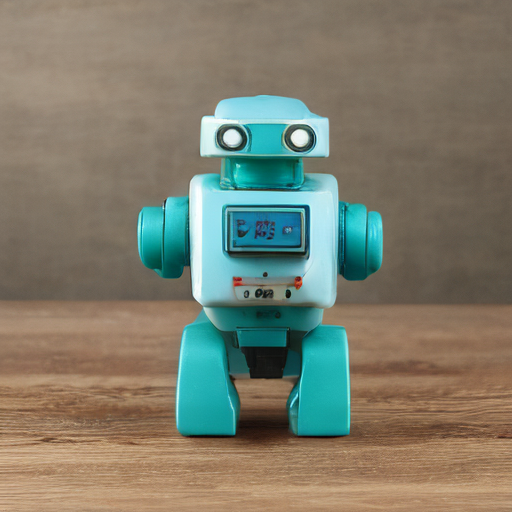

In [6]:

def generate_image(prompt, seed=SEED):
    generator = torch.Generator(
        device=DEVICE
    ).manual_seed(seed)

    return text_to_image(
        prompt=prompt,
        width=512,
        height=512,
        num_inference_steps=1,
        guidance_scale=0.0,
        generator=generator
    ).images[0]


baseline_path = "images/baseline_robot.png"

if os.path.exists(baseline_path):
    baseline_image = Image.open(
        baseline_path
    ).convert("RGB")
else:
    baseline_image = generate_image(
        BASELINE_PROMPT
    )
    baseline_image.save(baseline_path)

print("Baseline image:")
display(baseline_image)


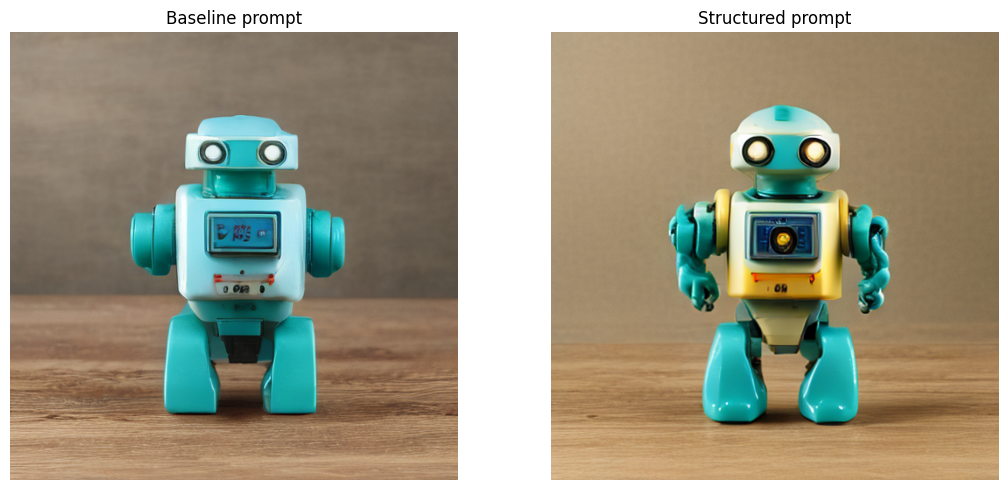

In [7]:

structured_path = "images/structured_robot.png"

if os.path.exists(structured_path):
    structured_image = Image.open(
        structured_path
    ).convert("RGB")
else:
    structured_image = generate_image(
        STRUCTURED_PROMPT
    )
    structured_image.save(structured_path)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].imshow(baseline_image)
axes[0].set_title("Baseline prompt")
axes[0].axis("off")

axes[1].imshow(structured_image)
axes[1].set_title("Structured prompt")
axes[1].axis("off")

plt.tight_layout()
plt.show()



## 3. Image-to-Image Prompting

We will now use the structured image as
the input to a second generation process.

### Objective

Transform the robot's surroundings from
a studio setting to a warm, cozy library.

### Desired changes

- Add a library environment.
- Introduce warm evening lighting.
- Show bookshelves in the background.

### Desired preservation

- Keep a teal ceramic robot.
- Preserve the subject's overall appearance.
- Retain identifiable features where possible.

Image-to-image diffusion does not guarantee
exact preservation.

The model adds noise to the input image and
reconstructs it under the new prompt.

We use moderate transformation strength,
balancing visual change and continuity.

This experiment is different from precise
masked editing or ControlNet conditioning.


You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion_img2img.StableDiffusionImg2ImgPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


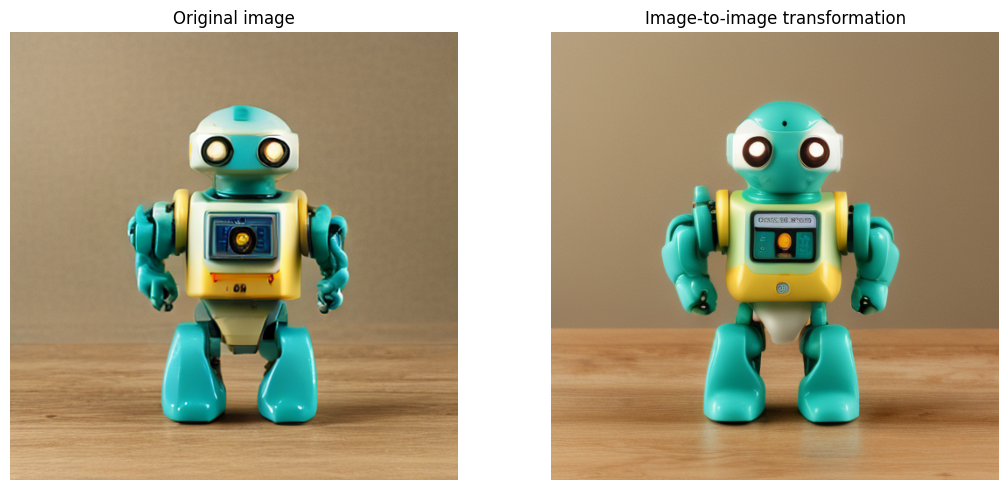

In [8]:

image_to_image = (
    AutoPipelineForImage2Image.from_pipe(
        text_to_image
    ).to(DEVICE)
)

image_to_image.set_progress_bar_config(
    disable=True
)

EDIT_PROMPT = (
    "Product photograph of the same small teal "
    "ceramic robot with rounded head, amber eyes "
    "and yellow star on its chest, sitting on a "
    "wooden desk in a cozy library, softly blurred "
    "bookshelves in the background, warm evening "
    "light, realistic photograph."
)

edited_path = "images/edited_robot.png"

if os.path.exists(edited_path):
    edited_image = Image.open(
        edited_path
    ).convert("RGB")
else:
    generator = torch.Generator(
        device=DEVICE
    ).manual_seed(SEED)

    edited_image = image_to_image(
        prompt=EDIT_PROMPT,
        image=structured_image.resize((512, 512)),
        strength=0.5,
        num_inference_steps=2,
        guidance_scale=0.0,
        generator=generator
    ).images[0]

    edited_image.save(edited_path)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].imshow(structured_image)
axes[0].set_title("Original image")
axes[0].axis("off")

axes[1].imshow(edited_image)
axes[1].set_title("Image-to-image transformation")
axes[1].axis("off")

plt.tight_layout()
plt.show()



## 4. Evaluate Prompt Adherence

Image generation should be evaluated against
observable requirements rather than prompt length.

We will manually assess three dimensions.

### Baseline generation

Does the output show the requested general subject?

### Structured generation

Did the model follow the additional instructions
for color, facial features, composition and style?

### Image-to-image transformation

Did the model produce the intended new environment?

Did the original subject remain recognizable?

A correct environmental transformation with
major changes to the robot would represent
partial success, not complete success.

Visual judgments are recorded explicitly
so the experiment can be reviewed later.


In [10]:

criteria = {
    "baseline": [
        "A robot is visible",
        "The robot is teal",
        "The scene contains a wooden desk"
    ],
    "structured": [
        "A single teal ceramic robot is visible",
        "The robot has amber eyes",
        "The robot has a yellow chest star",
        "The subject is fully visible and centered",
        "The background resembles a clean studio"
    ],
    "edited": [
        "The environment resembles a library",
        "The lighting appears warm",
        "The robot is still recognizable",
        "Key robot features are retained"
    ]
}

print("Inspect the images shown in Cells 9 and 11.")
print("Enter y or n for each criterion.\n")

observations = []

for stage, checks in criteria.items():
    print(f"\n{stage.upper()}")

    for criterion in checks:
        while True:
            answer = input(
                f"{criterion} [y/n]: "
            ).strip().lower()

            if answer in ("y", "n"):
                break

            print("Enter y or n.")

        observations.append({
            "Stage": stage,
            "Criterion": criterion,
            "Passed": answer == "y"
        })

evaluation_df = pd.DataFrame(observations)

print("\nEVALUATION RESULTS")
print(evaluation_df.to_string(index=False))

summary = (
    evaluation_df
    .groupby("Stage")["Passed"]
    .agg(["sum", "count"])
)

summary["rate"] = (
    summary["sum"] / summary["count"]
)

print("\nSUMMARY")
print(summary)

print(
    "\nScores represent human visual judgments,"
    " not automated model-quality measurements."
)


Inspect the images shown in Cells 9 and 11.
Enter y or n for each criterion.


BASELINE
A robot is visible [y/n]: y
The robot is teal [y/n]: y
The scene contains a wooden desk [y/n]: y

STRUCTURED
A single teal ceramic robot is visible [y/n]: y
The robot has amber eyes [y/n]: y
The robot has a yellow chest star [y/n]: y
The subject is fully visible and centered [y/n]: y
The background resembles a clean studio [y/n]: y

EDITED
The environment resembles a library [y/n]: n
The lighting appears warm [y/n]: y
The robot is still recognizable [y/n]: y
Key robot features are retained [y/n]: n

EVALUATION RESULTS
     Stage                                 Criterion  Passed
  baseline                        A robot is visible    True
  baseline                         The robot is teal    True
  baseline          The scene contains a wooden desk    True
structured    A single teal ceramic robot is visible    True
structured                  The robot has amber eyes    True
structured         The


## Findings and Limitations

### What This Notebook Demonstrates

- Baseline and structured image prompting.
- Text-to-image generation with a pretrained
  Stable Diffusion model.
- Controlled comparison using the same random seed.
- Specification of visual attributes,
  composition, background and lighting.
- Image-to-image transformation using
  a reference image and new text prompt.
- Evaluation of instruction adherence.
- Assessment of subject preservation.

### Prompt Engineering Techniques

**Visual specificity**

The structured prompt provides identifying
details beyond the general subject description.

**Composition instructions**

The prompt specifies framing and positioning.

**Environment and lighting**

Prompts describe where the subject appears
and how the scene is illuminated.

**Reference-image conditioning**

The editing stage uses an existing image
as input to a diffusion pipeline.

**Preservation instructions**

The editing prompt repeats identifying
features that should remain recognizable.

**Controlled comparison**

The generation settings and seed are held
constant between the initial prompts.


### Observed Results

Three images were generated using Stable Diffusion
Turbo: a baseline image, a structured-prompt image,
and an image-to-image transformation.

The images were evaluated manually against
predefined visual requirements.

| Stage | Criteria satisfied | Result |
|---|---:|---:|
| Baseline | 3/3 | 100% |
| Structured | 5/5 | 100% |
| Image-to-image editing | 2/4 | 50% |

**Baseline generation**

The baseline image satisfied all three basic
requirements: a visible teal robot positioned
on a wooden desk.

**Structured prompting**

The structured image satisfied all five
evaluated criteria:

- A single teal ceramic robot.
- Amber-colored eyes.
- A yellow chest star.
- Centered, full-body composition.
- A clean studio-like background.

The detailed prompt successfully communicated
the evaluated visual attributes.

**Image-to-image transformation**

The edited image retained a recognizable teal
robot and exhibited warmer lighting.

However, the requested library environment
was not generated. The background remained
similar to the original studio scene.

Several robot details also changed during
the transformation, including facial and
chest features.

Only two of the four editing criteria
were satisfied.

**Interpretation**

The image-generation prompts produced images
consistent with their evaluated requirements.

However, the baseline and structured prompts
used different checklists, so their scores
cannot establish a quantitative improvement
from increased prompt detail alone.

The image-to-image experiment demonstrated
partial preservation of the original subject,
but limited control over the requested scene
transformation.

This illustrates an important distinction:
a detailed prompt may specify the intended
changes clearly, while the model may still
fail to implement them.

The observed editing limitations may depend
on the model, transformation strength,
generation settings and prompt wording.

### Key Takeaway

Advanced image prompting involves more than
describing the desired output.

Successful prompting requires evaluating
whether the model follows specific visual
instructions and identifying which details
remain difficult to control.


### Limitations

- The experiment uses only one fictional subject.
- Each initial prompt is evaluated once.
- The two prompts differ in several dimensions,
  so no single instruction can be isolated.
- A fixed seed improves comparison consistency
  but does not eliminate all variation.
- SD-Turbo may not reliably follow complex
  visual or spatial instructions.
- The model's 512×512 outputs are relatively small.
- Image-to-image diffusion may alter the subject.
- Transformation strength influences the amount
  of visual change independently of prompt wording.
- The visual evaluation uses human judgments.
- No automated perceptual similarity metric
  or statistical analysis is included.
- Precise mask-based editing is not implemented.

### Conclusion

This notebook demonstrates how image prompt
specificity and reference-image conditioning
influence generated visual outputs.

The baseline and structured prompts allow
a direct visual comparison under similar
generation settings.

Image-to-image prompting demonstrates how
an existing image can be transformed using
a new textual description.


The image-to-image experiment demonstrates that
prompt instructions alone do not guarantee precise
editing. Although the robot remained recognizable,
the model failed to produce the requested library
environment and altered some identifying features.
This highlights the limitations of general
image-to-image diffusion when precise subject
preservation and background control are required.


The experiment emphasizes observable
instruction adherence and transparent
evaluation rather than assuming successful
generation implies successful prompting.
